In [1]:
from lib import *
from lib_models import *
import numpy as np
import pandas as pd

In [2]:
import torch
from torch.utils.data import DataLoader

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

In [ ]:
import pytorch_lightning as L 
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

# load features from memmap & verify

In [5]:
mm_eeg = load_eeg_memmap()

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


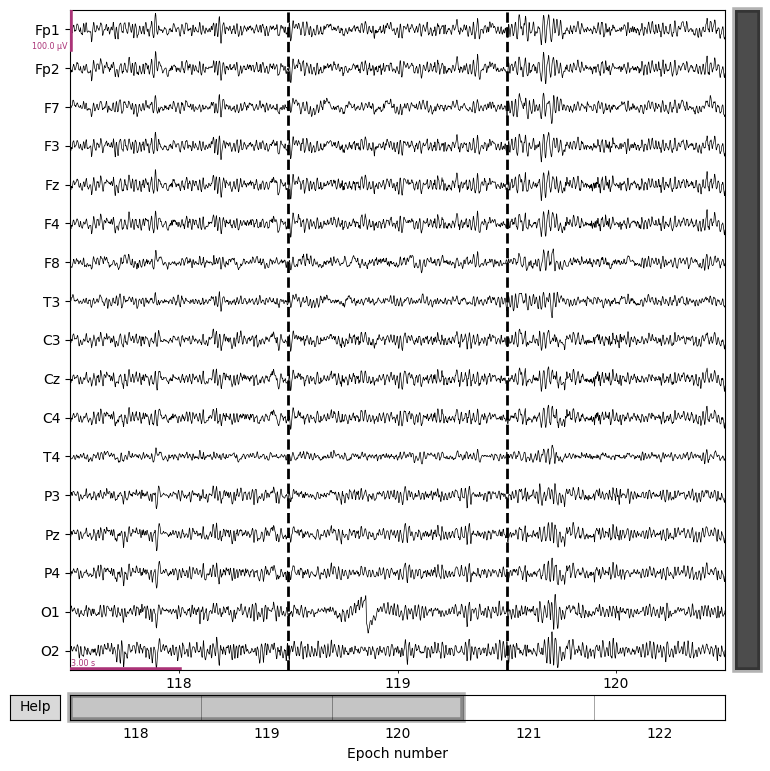

In [6]:
g = plot_epoch_eeg(mm_eeg[102], start_epoch = 118, end_epoch = 123, n_epochs_to_plot = 3)

In [7]:
mm_conn, S00_exams_indices, N_S00_exams  = load_s00_conn_memmap()

In [8]:
mm_conn.shape

(1697, 150, 17, 17, 5)

There are 1697 recordings from S00 (in the processed database). Each has 5 band-wise adjacency matrices of ffDTF metric.

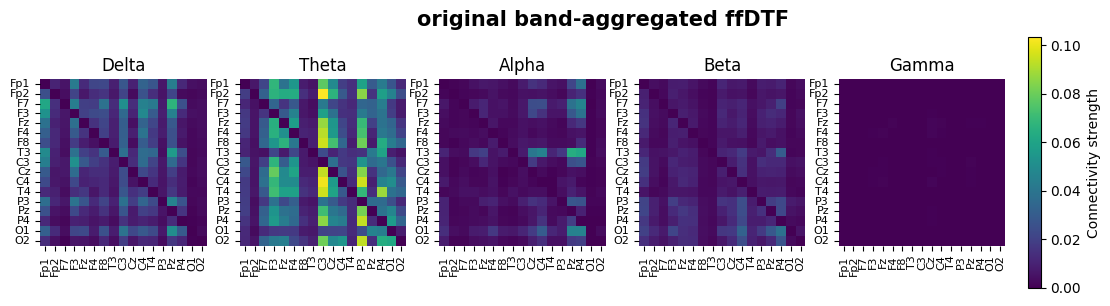

In [9]:
heatmap_bands(mm_conn[102][120])

# data utilities

## dataset

Let's treat the bands dimension as colors in RGB

Crate data splits with sklearn's [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

In [10]:
meta = read_metadata()
labels = np.asarray(meta['pathology']).astype(int)[:N_S00_exams]
patients = np.asarray(meta['patient_id'])[:N_S00_exams]
sex = np.asarray(meta['female']).astype(int)[:N_S00_exams]
age = np.asarray(meta['age_group'])[:N_S00_exams]

In [11]:
# stratify on label (+ optionally sex/age), group by patient so none is in both splits
#strata = labels.astype(str)                        # or: np.char.add(labels.astype(str), sex.astype(str))

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
folds_train_indieces = []
folds_val_indieces = []
for i, (train_index, test_index) in enumerate(sgkf.split(X = S00_exams_indices, 
                                             y = labels, 
                                             groups=patients)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[:10]}")
    print(f"         group={patients[train_index][:10]}")
    print(f"  Test:  index={test_index[:10]}")
    print(f"         group={patients[test_index][:10]}")
    folds_train_indieces.append(train_index)
    folds_val_indieces.append(test_index)

Fold 0:
  Train: index=[ 0  1  2  4  6  7  8  9 10 12]
         group=['P27809' 'P27811' 'P27812' 'P27819' 'P27799' 'P27802' 'P27826' 'P27852'
 'P27854' 'P27863']
  Test:  index=[ 3  5 11 16 20 23 32 43 47 49]
         group=['P27818' 'P27804' 'P27861' 'P27839' 'P15082' 'P15056' 'P27984' 'P28012'
 'P28004' 'P28007']
Fold 1:
  Train: index=[ 0  1  3  4  5  7  8  9 10 11]
         group=['P27809' 'P27811' 'P27818' 'P27819' 'P27804' 'P27802' 'P27826' 'P27852'
 'P27854' 'P27861']
  Test:  index=[ 2  6 13 17 18 25 28 33 42 50]
         group=['P27812' 'P27799' 'P27867' 'P27843' 'P15085' 'P15067' 'P15063' 'P27988'
 'P28015' 'P28010']
Fold 2:
  Train: index=[ 1  2  3  5  6  7  8 10 11 12]
         group=['P27811' 'P27812' 'P27818' 'P27804' 'P27799' 'P27802' 'P27826' 'P27854'
 'P27861' 'P27863']
  Test:  index=[ 0  4  9 22 27 31 36 37 51 54]
         group=['P27809' 'P27819' 'P27852' 'P15104' 'P15064' 'P27982' 'P27968' 'P28018'
 'P28011' 'P27891']
Fold 3:
  Train: index=[ 0  2  3  4  5  6  7  

In [12]:
train_dataset = S00MILDataset(folds_train_indieces[0], max_instances=150,train=True)
val_dataset = S00MILDataset(folds_val_indieces[0], max_instances=150,train=False)

In [13]:
train_loader = DataLoader(train_dataset, 
                          batch_size=10, 
                          shuffle=True,  
                          num_workers=8, 
                          pin_memory=True)

val_loader = DataLoader(val_dataset,  
                        batch_size=10, 
                        shuffle=False, 
                        num_workers=8, 
                        pin_memory=True)

## let's see if the model works

Quick sanity check before real training

In [15]:
x, y = next(iter(train_loader))
print(x.shape, x.dtype)                      # expect (N, W, 5, 17, 17), float32
assert x.shape[-2:] == (17, 17)

model = BagEncoder(ConvAE(latent=16))
model.eval()
with torch.no_grad():
    recon, z = model(x)
assert recon.shape == x.shape and z.shape == (x.shape[0], x.shape[1], 16)

torch.Size([10, 150, 5, 17, 17]) torch.float32


Smoke test that runs one train & one val epoch (bugs discovery)

In [16]:
trainer = L.Trainer(fast_dev_run=True, accelerator="auto")
trainer.fit(model, train_loader, val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━╇━━━━━━━┩
│ 0 │ ae   │ ConvAE │ 37.3 K │ eval │     0 │
└───┴──────┴────────┴────────┴──────┴───────┘

Trainable params: 37.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 37.3 K                                                                                               
Total estimated model params size (MB): 0.149                                                                      
Modules in train mode: 0                                                                                           
Modules in eval mode: 16                                                                                           
Total FLOPs: 0

Output()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/pytorch_lightning/loops/fit_loop.py:538: Found 17 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


`Trainer.fit` stopped: `max_steps=1` reached.


Overfit a tiny subset

In [17]:
trainer = L.Trainer(overfit_batches=2, 
                    max_epochs=100, 
                    accelerator="auto",
                    logger=CSVLogger("logs", name="conv_ae"))
model.train()
trainer.fit(model, train_loader, val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ ae   │ ConvAE │ 37.3 K │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 37.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 37.3 K                                                                                               
Total estimated model params size (MB): 0.149                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/pytorch_lightning/trainer/connecto
rs/data_connector.py:260: You requested to overfit but enabled train dataloader shuffling. We are turning off the 
train dataloader shuffling for you.

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/pytorch_lightning/loops/fit_loop.p
y:321: The number of training batches (2) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a
lower value for log_every_n_steps if you want to see logs for the training epoch.

`Trainer.fit` stopped: `max_epochs=100` reached.


In [20]:
ckpt = ModelCheckpoint(monitor="val_loss", 
                       mode="min", 
                       filename="ae_fold0")
trainer = L.Trainer(
    max_epochs=150,
    accelerator="auto",
    logger=CSVLogger("logs", name="ae_fold0"),
    callbacks=[EarlyStopping(monitor="val_loss", patience=10), ckpt],
)

model = BagEncoder(ConvAE(latent=16))
trainer.fit(model, train_loader, val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ ae   │ ConvAE │ 37.3 K │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 37.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 37.3 K                                                                                               
Total estimated model params size (MB): 0.149                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

In [21]:
best = BagEncoder.load_from_checkpoint(ckpt.best_model_path, ae=ConvAE(latent=16))
pred_trainer = L.Trainer(accelerator="auto", logger=False, enable_checkpointing=False)
out = pred_trainer.predict(best, val_loader) 

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
GPU available: False

Output()

In [22]:
recons  = torch.cat([r for r, _ in out]) #type:ignore       
latents = torch.cat([z for _, z in out]) #type:ignore  

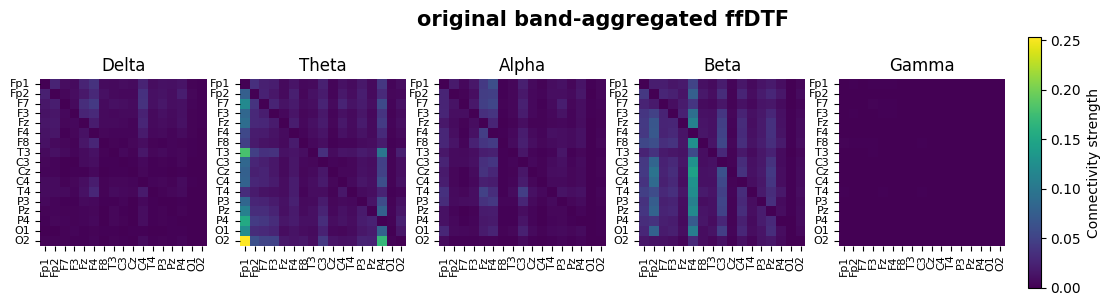

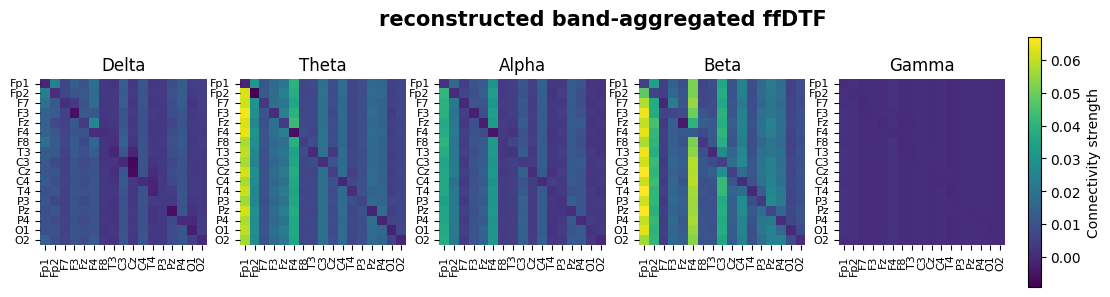

In [27]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 5, 
                 window_i = 45)

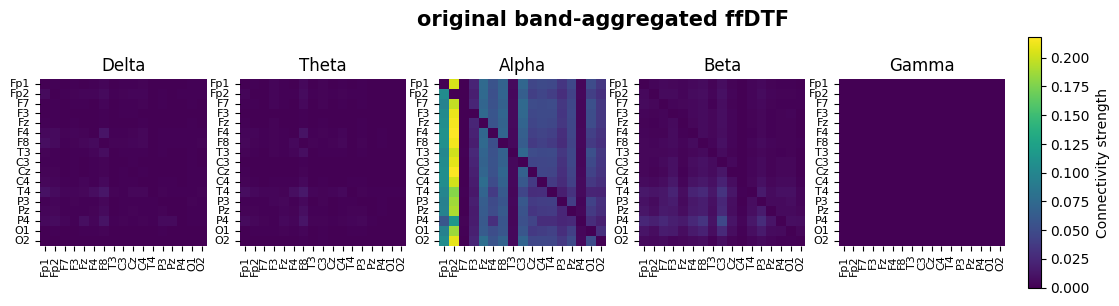

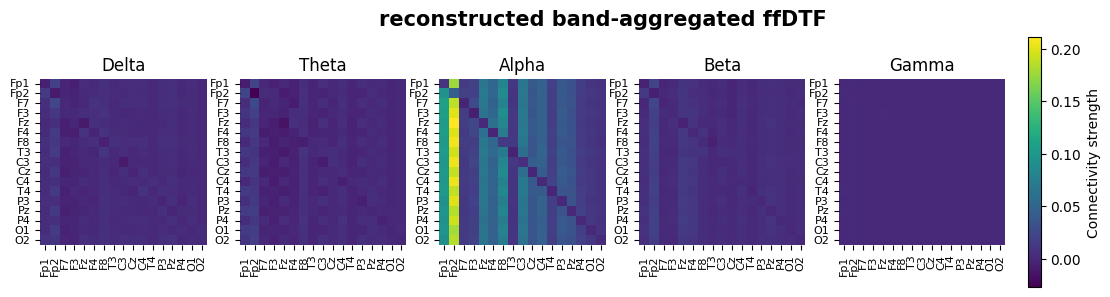

In [26]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 50, 
                 window_i = 120)

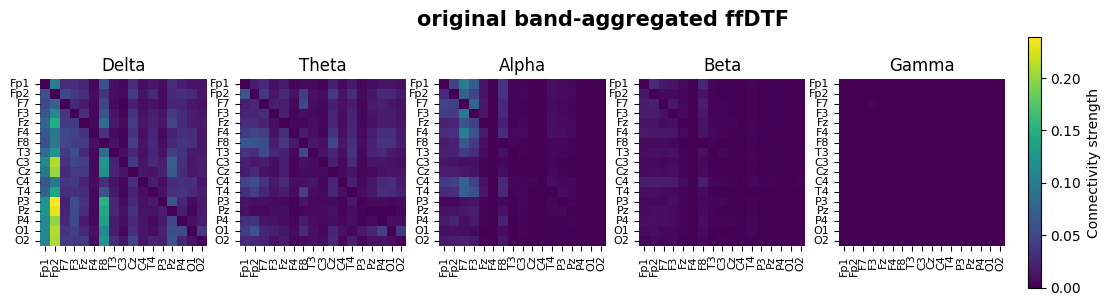

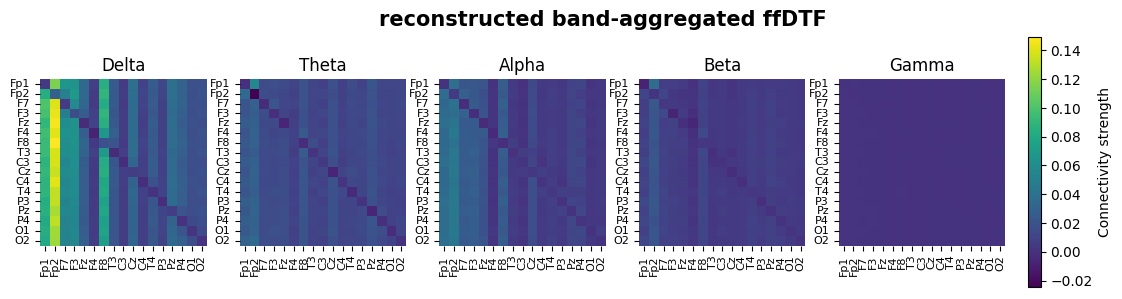

In [29]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 333, 
                 window_i = 20)

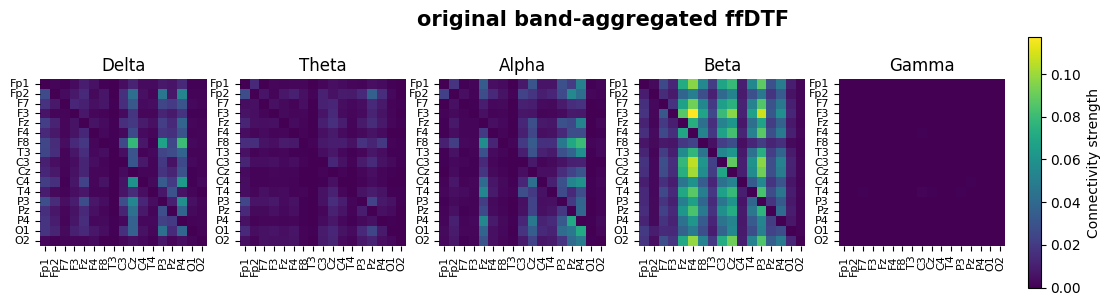

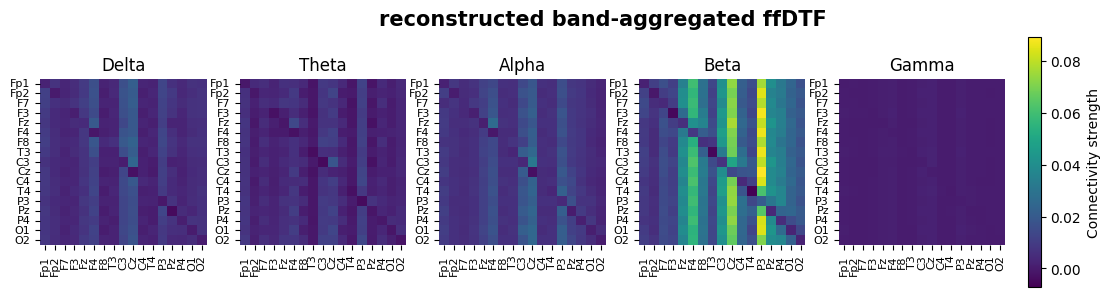

In [30]:
compare_heatmaps(val_ds = val_dataset, 
                 connectivity_mm = mm_conn, 
                 reconstructed = recons, 
                 recon_i = 13, 
                 window_i = 87)

It seems that the most basic convolution autoencoder is good for identifying source vertical lines. It shows the tendency to overpower pixels that originally have lower values.